# 1.8 Running the model in GreenLight

## Live code in this page

This page uses **live code**. Click the rocket button (🚀) at the top of this page, above the title, then choose "▶ Live Code". The loading may take some time so it is good to start the Live Code before reading on. The Live Code engine is ready when you see a text under the page's title, stating something like "Launching from mybinder.org: **ready**.

**Note:** Code that you edit in the live code blocks is not saved. Any changes you make to the code blocks is lost once you move on from the page. Therefore, if you want to keep your work, save a copy of it in a local document.

The code block below defines some imports and functions that will be helpful in the current page. It is run automatically when you run the "▶ Live Code" button. You may have a look at it if you like, but that is not neccesary for this course.

In [52]:
%matplotlib widget

import os
import pandas as pd
import matplotlib.pyplot as plt
from urllib.request import urlretrieve
import greenlight

def display_dict(d):
    """
    Below, some dictionaries will be define in the standard
    GreenLight format for describing models.
    This functions displays such dictionaries in a nicely
    readable format
    """
    df = pd.DataFrame.from_dict(d, orient="index")
    df.index.name = "Variable"
    display(df)

## What we have so far

At the end of the previous section, we've finished defining the simple crop model in a Python dict. Run the code block below to load this dict into the variable `crop_definition`.

In [53]:
"""
Solution to Exercise 6: replace the definition of the input variable I with a definition of Iw, as above
"""

crop_definition = {
    "W": {
        "description": "Crop dry mass",
        "unit": "g/m2",
        "type": "state",
        "reference": "Stanghellini (2019), Eq. 2.25",
        "definition": "LUE * ( 1 - exp(-k*LAI) ) * 1/1000000 * Iw",  # I is replaced by 1/1000000 * Iw
        "init": "75"  
    },
    "LUE": {
        "description": "Light use efficiency",
        "unit": "g crop weight per MJ PAR",
        "type": "const",
        "reference": "Stanghellini (2019), Eq. 2.25",
        "definition": "4.3"  
    },
    "k": {
        "description": "Light extinction coefficient",
        "unit": "-",
        "type": "const",
        "reference": "Stanghellini (2019), Eq. 2.25",
        "definition": "0.7"  
    },
    "LAI": {
        "description": "Leaf area index",
        "unit": "m2 leaf per m2 floor",
        "type": "aux",
        "reference": "Stanghellini (2019), Eq. 2.25",
        "definition": "W * fLeaves * SLA / 10000"  
    },
    "Iw": {  # I is replaced by Iw
        "description": "PAR intensity",  # This variable is instanenous, rather than daily, values
        "unit": "W PAR per m2",  # The unit is now W PAR per m2
        "type": "input",
        "reference": "Stanghellini (2019), Eq. 2.25, adjusting I (in MJ/m2/day) to Iw (in W/m2)",  # Add information in reference
        "definition": "200"
    },
    "fLeaves": {
        "description": "Fraction of crop dry mass partitioned to the leaves",
        "unit": "-",
        "type": "const",
        "reference": "Stanghellini (2019), Eq. 2.26",
        "definition": "0.8" 
    },
    "SLA": {
        "description": "Specific leaf area",
        "unit": "cm2/g",
        "type": "const",
        "reference": "Stanghellini (2019), Eq. 2.26",
        "definition": "250"  
    }   
 }

# Display the above dict
display_dict(crop_definition)

,description,unit,type,reference,definition,init
Variable,,,,,,
W,Crop dry mass,g/m2,state,"Stanghellini (2019), Eq. 2.25",LUE * ( 1 - exp(-k*LAI) ) * 1/1000000 * Iw,75
LUE,Light use efficiency,g crop weight per MJ PAR,const,"Stanghellini (2019), Eq. 2.25",4.3,NaN
k,Light extinction coefficient,-,const,"Stanghellini (2019), Eq. 2.25",0.7,NaN
LAI,Leaf area index,m2 leaf per m2 floor,aux,"Stanghellini (2019), Eq. 2.25",W * fLeaves * SLA / 10000,NaN
Iw,PAR intensity,W PAR per m2,input,"Stanghellini (2019), Eq. 2.25, adjusting I (in...",200,NaN
fLeaves,Fraction of crop dry mass partitioned to the l...,-,const,"Stanghellini (2019), Eq. 2.26",0.8,NaN
SLA,Specific leaf area,cm2/g,const,"Stanghellini (2019), Eq. 2.26",250,NaN


## Getting input data

The crop model we've defined requires **input data**. Specifically, we've defined the **input variable `Iw`** which is the **PAR intensity above the crop**, in **W/m<sup>2</sup>**. In the following code block, we download the required input data and place it where the engine running the code blocks can access it. You can find more information about this input data [here](https://github.com/davkat1/intro_gh_modelling_draft/tree/main/notebooks/input).

In [54]:
"""
Download input data for the crop model from https://github.com/davkat1/intro_gh_modelling_draft/tree/main/notebooks/input/Crop_model_input_Bleiswijk_from_20091020.csv
And place it under the current working directory
"""

# Create folder called "input"
if not os.path.exists("input"):
    os.makedirs("input")
    
# Download the file from github
url = "https://raw.githubusercontent.com/davkat1/intro_gh_modelling_draft/refs/heads/main/notebooks/input/Crop_model_input_Bleiswijk_from_20091020.csv"
saved_input = os.path.abspath(os.path.join("input", "Crop_model_input_Bleiswijk_from_20091020.csv"))
urlretrieve(url, saved_input)

# Load the data to a DataFrame and show it in a table
input_df = pd.read_csv(saved_input, header=[0, 1, 2])
display(input_df)

,Time,Iw
,Time since start of data,Outdoor solar PAR radiation
,s,W m**-2
0,0,0.000000
1,300,0.000000
2,600,0.000000
3,900,0.000000
4,1200,0.000000
...,...,...
31963,9588900,0.000119
31964,9589200,0.000000


### Displaying the input data in a graph

The code block below displays a part of the input data in a graph. It does so by considering that `input_df` now has two columns:
- `input_df.iloc[:, 0]` is the time unit (in seconds)
- `input_df.iloc[:, 1]` is the solar PAR (in W/m2)

The data is provided in 300 seconds intervals (5 minutes), which means every 288 rows represent one day.
Since seconds is not the most conveniet unit to display, we display the time unit in hours:

Output()

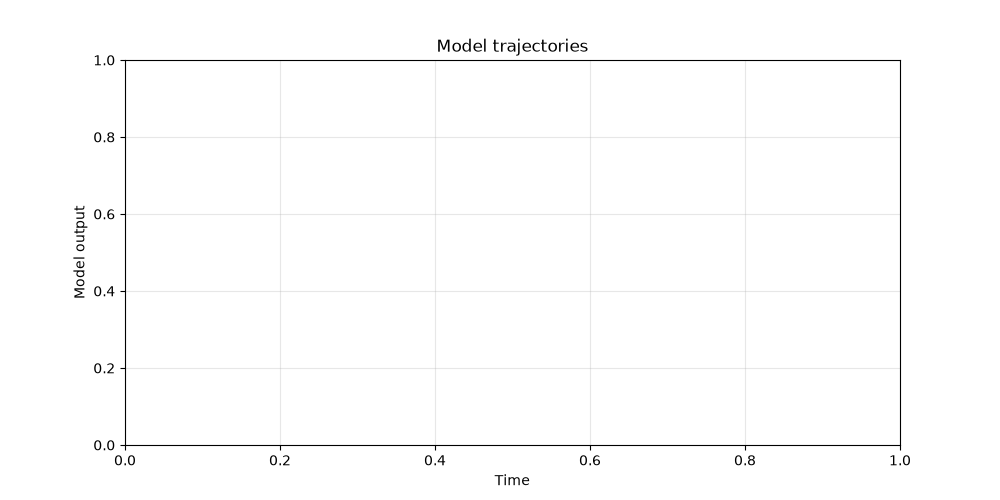

In [61]:
import traceback
import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import display, clear_output

slider_names = [
    "W init",
    "Iw",
    "LUE"
]


output = widgets.Output()

# --------------------------------------------------
# 1. Define the input sliders
# --------------------------------------------------

slider_1 = widgets.FloatSlider(
    value=75,
    min=0,
    max=250,
    step=0.1,
    description=slider_names[0],
    continuous_update=False
)

slider_2 = widgets.FloatSlider(
    value=200,
    min=0,
    max=1000,
    step=1,
    description=slider_names[1],
    continuous_update=False
)

slider_3 = widgets.IntSlider(
    value=4.3,
    min=0,
    max=20,
    step=0.01,
    description=slider_names[2],
    continuous_update=False
)


# --------------------------------------------------
# 2. Define the buttons
# --------------------------------------------------

run_button = widgets.Button(
    description='Run model',
    button_style='success',
    icon='play'
)

delete_button = widgets.Button(
    description='Delete latest curve',
    button_style='danger',
    icon='trash'
)


# --------------------------------------------------
# 3. Set up the plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_xlabel('Time')
ax.set_ylabel('Model output')
ax.set_title('Model trajectories')
ax.grid(True, alpha=0.3)

# Store the curves and their labels
curves = []


# --------------------------------------------------
# 4. Function to run the model
# --------------------------------------------------
import copy

def run_model(button):

    try:
        # Read slider values
        p1 = slider_1.value
        p2 = slider_2.value
        p3 = slider_3.value

        crop_definition_new = copy.deepcopy(crop_definition)
        crop_definition_new["W"]["init"] = str(p1)
        crop_definition_new["Iw"]["definition"] = str(p2)
        crop_definition_new["LUE"]["definition"] = str(p3)
        
        # Create a new model
        model = greenlight.GreenLight(input_prompt=crop_definition_new)

    
        # Run the model
        model.run()

    
        # Read the output file
        data = model.full_sol
        
        
        # Add a new curve
        line, = ax.plot(
            data.iloc[:, 0]/3600,
            data.iloc[:, 1],
            label=f"Run {len(curves)+1} - " +
                f"{slider_names[0]}: {p1}, " +
                f"{slider_names[1]}: {p2}, " +
                f"{slider_names[2]}: {p3} "
            
        )
        
        curves.append(line)
        
        ax.legend()

        display(fig)


    except Exception as e:
        traceback.print_exc()


# --------------------------------------------------
# 5. Function to delete the latest curve
# --------------------------------------------------

def delete_latest(button):

    if curves:

        # Remove the most recent curve
        line = curves.pop()
        line.remove()

        # Update legend
        ax.legend(loc='best')

        fig.canvas.draw_idle()


# --------------------------------------------------
# 6. Connect buttons to functions
# --------------------------------------------------

run_button.on_click(run_model)
delete_button.on_click(delete_latest)


# --------------------------------------------------
# 7. Display the interface
# --------------------------------------------------

controls = widgets.VBox([
    widgets.HTML('<h3>Model parameters</h3>'),
    slider_1,
    slider_2,
    slider_3,
    widgets.HBox([
        run_button,
        delete_button
    ])
])

display(controls)
display(output)